In [ ]:
#Install Libraries
!pip install xgboost imbalanced-learn -q

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving credit_card_fraud_xgboost_smote.csv to credit_card_fraud_xgboost_smote.csv


In [ ]:
df = pd.read_csv("credit_card_fraud_xgboost_smote.csv")

In [ ]:
df.head()

,transaction_id,transaction_amount,transaction_hour,distance_from_home_km,merchant_risk_score,device_risk_score,transactions_last_24h,avg_amount_last_30d,international,card_present,failed_attempts,account_age_days,merchant_category,channel,is_fraud
0,100000,40.31,9,0.65,13.73,64.07,5,17.84,1,0,0,1982,grocery,POS,0
1,100001,21.36,12,5.46,51.49,38.08,1,126.58,0,1,1,2775,restaurant,online,0
2,100002,46.88,8,0.58,26.48,55.14,2,6.52,0,1,2,2828,grocery,online,0
3,100003,112.51,5,1.32,21.89,56.96,1,27.32,0,1,1,652,grocery,POS,0
4,100004,19.41,14,1.84,17.61,36.87,2,14.79,0,0,0,747,electronics,online,0


In [ ]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["is_fraud"].value_counts())

print("\nTarget percentage:")
print(df["is_fraud"].value_counts(normalize=True) * 100)

Shape: (12000, 15)

Columns:
Index(['transaction_id', 'transaction_amount', 'transaction_hour',
       'distance_from_home_km', 'merchant_risk_score', 'device_risk_score',
       'transactions_last_24h', 'avg_amount_last_30d', 'international',
       'card_present', 'failed_attempts', 'account_age_days',
       'merchant_category', 'channel', 'is_fraud'],
      dtype='object')

Missing values:
transaction_id           0
transaction_amount       0
transaction_hour         0
distance_from_home_km    0
merchant_risk_score      0
device_risk_score        0
transactions_last_24h    0
avg_amount_last_30d      0
international            0
card_present             0
failed_attempts          0
account_age_days         0
merchant_category        0
channel                  0
is_fraud                 0
dtype: int64

Target distribution:
is_fraud
0    11700
1      300
Name: count, dtype: int64

Target percentage:
is_fraud
0    97.5
1     2.5
Name: proportion, dtype: float64


In [ ]:
X = df.drop(columns=["transaction_id", "is_fraud"])
y = df["is_fraud"]

In [ ]:
X = df.drop(columns=["transaction_id", "is_fraud"])
y = df["is_fraud"]

In [ ]:
numeric_features = [
    "transaction_amount",
    "transaction_hour",
    "distance_from_home_km",
    "merchant_risk_score",
    "device_risk_score",
    "transactions_last_24h",
    "avg_amount_last_30d",
    "international",
    "card_present",
    "failed_attempts",
    "account_age_days"
]

categorical_features = [
    "merchant_category",
    "channel"
]

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [ ]:
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

In [ ]:
smote = SMOTE(
    sampling_strategy=0.5,
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_encoded,
    y_train
)

In [ ]:
model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [ ]:
model.fit(X_train_smote, y_train_smote)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.85, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=6, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=300, n_jobs=-1,
              num_parallel_tree=None, ...)

In [ ]:
y_prob = model.predict_proba(X_test_encoded)[:, 1]

In [ ]:
print(y_prob[:10])

[1.6026886e-03 3.5011801e-03 7.9845733e-05 7.9695732e-05 3.5994235e-05
 1.1041461e-05 1.4694533e-04 4.5179764e-05 2.5250418e-02 1.0350237e-03]


In [ ]:
thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    precision = precision_score(
        y_test,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        y_pred,
        zero_division=0
    )

    results.append([
        threshold,
        precision,
        recall,
        f1
    ])

threshold_df = pd.DataFrame(
    results,
    columns=["Threshold", "Precision", "Recall", "F1"]
)

threshold_df

,Threshold,Precision,Recall,F1
0,0.10,0.610526,0.966667,0.748387
1,0.15,0.695122,0.950000,0.802817
2,0.20,0.729730,0.900000,0.805970
3,0.25,0.764706,0.866667,0.812500
4,0.30,0.757576,0.833333,0.793651
5,0.35,0.777778,0.816667,0.796748
6,0.40,0.790323,0.816667,0.803279
7,0.45,0.796610,0.783333,0.789916
8,0.50,0.818182,0.750000,0.782609
9,0.55,0.826923,0.716667,0.767857


In [ ]:
best_threshold = threshold_df.loc[
    threshold_df["F1"].idxmax(),
    "Threshold"
]

print("Best Threshold:", best_threshold)

Best Threshold: 0.25000000000000006


In [ ]:
y_pred = (y_prob >= best_threshold).astype(int)

In [ ]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("ROC-AUC  :", roc_auc)

Accuracy : 0.99
Precision: 0.7647058823529411
Recall   : 0.8666666666666667
F1 Score : 0.8125
ROC-AUC  : 0.9973290598290598


In [ ]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Normal       1.00      0.99      0.99      2340
       Fraud       0.76      0.87      0.81        60

    accuracy                           0.99      2400
   macro avg       0.88      0.93      0.90      2400
weighted avg       0.99      0.99      0.99      2400



In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[2324   16]
 [   8   52]]


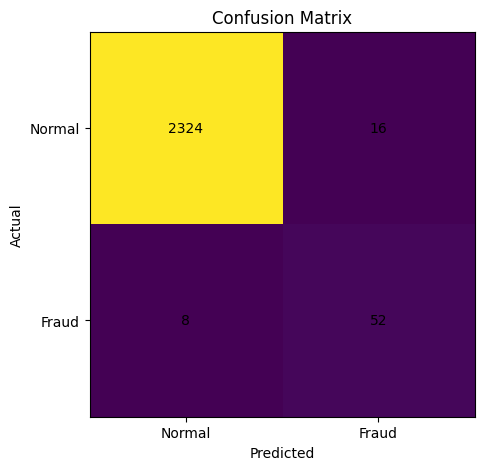

In [ ]:
plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Normal", "Fraud"])
plt.yticks([0, 1], ["Normal", "Fraud"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j],
                 ha="center",
                 va="center")

plt.show()

In [ ]:
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.head(15))

                             Feature  Importance
16          remainder__international    0.405285
17           remainder__card_present    0.247516
11  remainder__distance_from_home_km    0.071767
10       remainder__transaction_hour    0.049677
2     cat__merchant_category_grocery    0.031985
13      remainder__device_risk_score    0.031608
12    remainder__merchant_risk_score    0.031502
14  remainder__transactions_last_24h    0.015861
3      cat__merchant_category_online    0.015126
7                   cat__channel_POS    0.014310
8                cat__channel_online    0.013798
18        remainder__failed_attempts    0.011520
1     cat__merchant_category_fashion    0.010603
6                   cat__channel_ATM    0.010040
19       remainder__account_age_days    0.007850


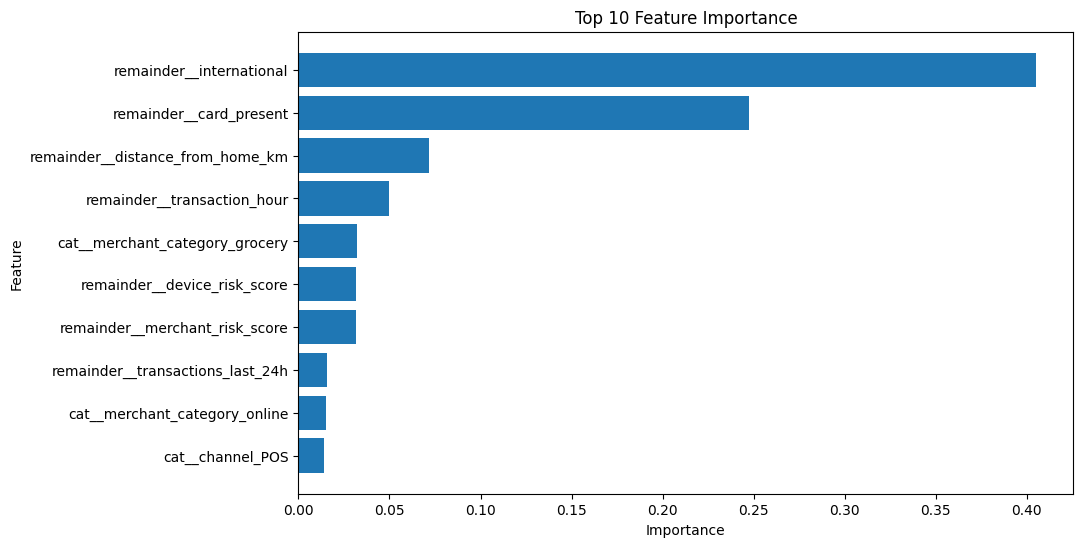

In [ ]:
top_features = importance_df.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importance")

plt.gca().invert_yaxis()

plt.show()